# Demo: load and visualize dataset by resolution & split
This notebook demonstrates how to load a single sample from the generated dataset for a specific resolution and split, and visualize the full image and the three tensor layers:

- Elevation (normalized float32) ✅
- Start / End markers (marker channel: -1 background, 0=start, 1=end) ✅
- Obstacles mask (binary) ✅

In [1]:
import datasets
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from passage.visualization import tensor_to_image
from passage.utils import decode_tensor_blob

/home/t0300081/projects/PASSAGE/passage/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Configuration: update these paths if needed
RESOLUTION = 256
SPLIT = "train"  # train / validation / test / calibration

# Load solver names from config
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

In [3]:
print(f"Resolution: {RESOLUTION}, Split: {SPLIT}")

Resolution: 256, Split: train


In [4]:
ds = datasets.load_dataset(
    "geoffrey-g-delhomme/passage",
    name=f"{RESOLUTION}x{RESOLUTION}",
)

In [5]:
sample = ds[SPLIT][np.random.randint(len(ds[SPLIT]))]
sample.keys()

dict_keys(['id', 'tensor', 'path_astar_elevation_free', 'path_astar_elevation_obstacles', 'path_astar_energy_free', 'path_astar_energy_obstacles', 'path_astar_slope_free', 'path_astar_slope_obstacles', 'metadata'])

In [6]:
if "image" in sample.keys():
    plt.imshow(sample["image"])
    plt.axis("off")
    plt.tight_layout()

In [11]:
metadata = sample["metadata"]
solvers = metadata["paths"].keys()

In [12]:
# Load paths for all solvers
solver_paths = {}
for solver_name in solvers:
    free_key = f"path_{solver_name}_free"
    obs_key = f"path_{solver_name}_obstacles"
    solver_paths[solver_name] = {
        "free": sample.get(free_key, []),
        "obstacles": sample.get(obs_key, []),
    }
    print(
        f"{solver_name}: free={len(solver_paths[solver_name]['free'])} pts, obstacles={len(solver_paths[solver_name]['obstacles'])} pts"
    )

metadata = sample["metadata"]
print(f"\nMetadata keys: {list(metadata.keys()) if isinstance(metadata, dict) else 'N/A'}")

astar_elevation: free=211 pts, obstacles=184 pts
astar_energy: free=253 pts, obstacles=268 pts
astar_slope: free=264 pts, obstacles=184 pts

Metadata keys: ['index', 'resolution', 'split', 'calibration', 'tile', 'crop', 'markers', 'obstacles', 'solvers', 'paths', 'timing', 'timestamp']


**NOTE**: Be careful, in order to optimize storage, tensors are saved in **compressed** format. They need to be uncompressed using `decode_tensor_blob` function!

In [13]:
tensor = decode_tensor_blob(sample["tensor"], (RESOLUTION, RESOLUTION, 3))
print("tensor.shape:", tensor.shape, "dtype:", tensor.dtype)

elevation = (
    tensor[:, :, 0] * (metadata["calibration"]["max"] - metadata["calibration"]["min"]) + metadata["calibration"]["min"]
)
marker = tensor[:, :, 1]
obstacles = tensor[:, :, 2]

print("Elevation min/max:", float(elevation.min()), float(elevation.max()))
print("Marker unique values:", np.unique(marker)[:10])
print("Obstacles unique values:", np.unique(obstacles)[:10])

tensor.shape: (256, 256, 3) dtype: float32
Elevation min/max: 1473.9998779296875 2613.0
Marker unique values: [-1.  0.  1.]
Obstacles unique values: [0. 1.]


In [14]:
img_bgr = tensor_to_image(tensor)
img_rgb = img_bgr[:, :, ::-1]

2026-01-30 21:07:46.787 | DEBUG    | passage.visualization:tensor_to_image:52 - tensor_to_image: elevation BEFORE normalization: min=0.2070, max=0.3309
2026-01-30 21:07:46.789 | DEBUG    | passage.visualization:tensor_to_image:98 - tensor_to_image: elevation AFTER normalization: min=0.0000, max=1.0000
2026-01-30 21:07:46.792 | DEBUG    | passage.visualization:tensor_to_image:134 - tensor_to_image: obst_count=%d, path_count=%d, start_count=%d, end_count=%d


2026-01-30 21:13:18.010 | DEBUG    | passage.visualization:tensor_to_image:52 - tensor_to_image: elevation BEFORE normalization: min=0.2070, max=0.3309
2026-01-30 21:13:18.011 | DEBUG    | passage.visualization:tensor_to_image:98 - tensor_to_image: elevation AFTER normalization: min=0.0000, max=1.0000
2026-01-30 21:13:18.015 | DEBUG    | passage.visualization:tensor_to_image:134 - tensor_to_image: obst_count=%d, path_count=%d, start_count=%d, end_count=%d
2026-01-30 21:13:18.017 | DEBUG    | passage.visualization:tensor_to_image:52 - tensor_to_image: elevation BEFORE normalization: min=0.2070, max=0.3309
2026-01-30 21:13:18.018 | DEBUG    | passage.visualization:tensor_to_image:98 - tensor_to_image: elevation AFTER normalization: min=0.0000, max=1.0000
2026-01-30 21:13:18.020 | DEBUG    | passage.visualization:tensor_to_image:134 - tensor_to_image: obst_count=%d, path_count=%d, start_count=%d, end_count=%d
2026-01-30 21:13:18.023 | DEBUG    | passage.visualization:tensor_to_image:52 - 

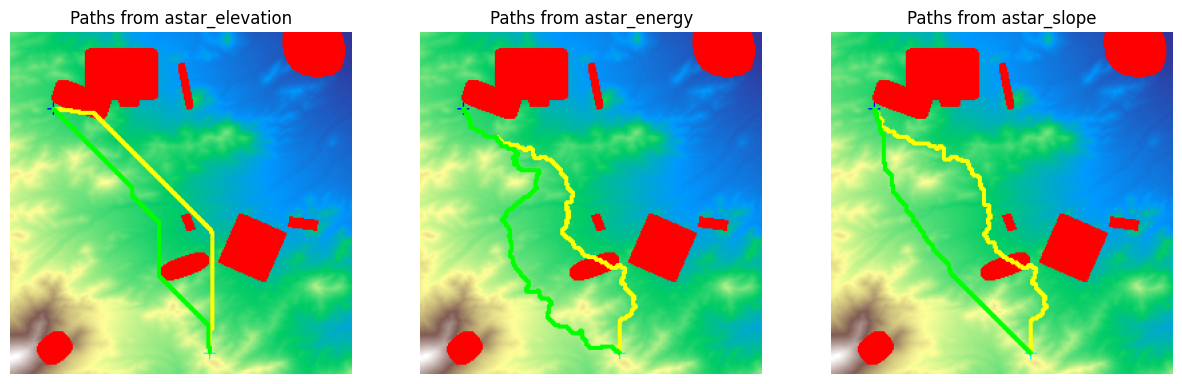

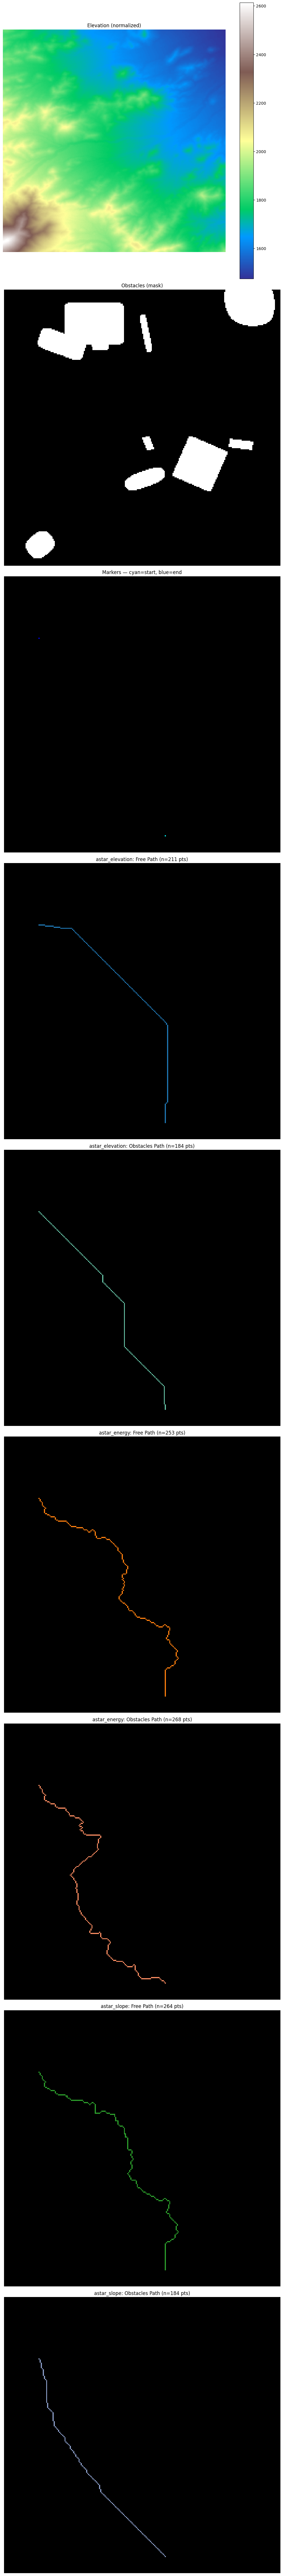

In [21]:
# Visualize each channel and paths for all solvers
n_solvers = len(solvers)
n_base_plots = 3  # Elevation, Obstacles, Markers
n_path_plots = n_solvers * 2  # free + obstacles for each solver
n_plots = n_base_plots + n_path_plots

fig, axes = plt.subplots(1, len(solvers), figsize=(15, 15 * len(solvers)))

for i, solver_name in enumerate(solvers):
    ax = axes[i]
    img_bgr = tensor_to_image(tensor, solver_paths[solver_name]["free"], solver_paths[solver_name]["obstacles"])
    img_rgb = img_bgr[:, :, ::-1]
    ax.imshow(img_rgb)
    ax.set_title(f"Paths from {solver_name}")
    ax.axis("off")

fig.show()

fig, axes = plt.subplots(n_plots, figsize=(10, 10 * n_plots))
if n_plots == 1:
    axes = [axes]

# 2. Elevation
ax = axes[0]
im = ax.imshow(elevation, cmap="terrain")
plt.colorbar(im, ax=ax)
ax.set_title("Elevation (normalized)")
ax.axis("off")

# 3. Obstacles
ax = axes[1]
ax.imshow(obstacles, cmap="gray")
ax.set_title("Obstacles (mask)")
ax.axis("off")

# 4. Markers
ax = axes[2]
start_mask = marker == 0.0
end_mask = marker == 1.0
combined = np.zeros((marker.shape[0], marker.shape[1], 3), dtype=np.uint8)
combined[start_mask] = [0, 255, 255]  # cyan for start
combined[end_mask] = [0, 0, 255]  # blue for end
ax.imshow(combined)
ax.set_title("Markers — cyan=start, blue=end")
ax.axis("off")

# 5+. Path visualizations per solver
colors_free = plt.cm.tab10.colors  # Different colors for each solver
colors_obs = plt.cm.Set2.colors
ax_idx = 3
for solver_idx, solver_name in enumerate(solvers):
    free_path = solver_paths[solver_name]["free"]
    obs_path = solver_paths[solver_name]["obstacles"]

    # Free path
    ax = axes[ax_idx]
    paths_img = np.zeros((marker.shape[0], marker.shape[1], 3), dtype=np.uint8)
    color_free = [int(c * 255) for c in colors_free[solver_idx % len(colors_free)][:3]]
    for x, y in free_path:
        if 0 <= x < paths_img.shape[0] and 0 <= y < paths_img.shape[1]:
            paths_img[x, y] = color_free
    ax.imshow(paths_img)
    ax.set_title(f"{solver_name}: Free Path (n={len(free_path)} pts)")
    ax.axis("off")
    ax_idx += 1

    # Obstacles path
    ax = axes[ax_idx]
    paths_img = np.zeros((marker.shape[0], marker.shape[1], 3), dtype=np.uint8)
    color_obs = [int(c * 255) for c in colors_obs[solver_idx % len(colors_obs)][:3]]
    for x, y in obs_path:
        if 0 <= x < paths_img.shape[0] and 0 <= y < paths_img.shape[1]:
            paths_img[x, y] = color_obs
    ax.imshow(paths_img)
    ax.set_title(f"{solver_name}: Obstacles Path (n={len(obs_path)} pts)")
    ax.axis("off")
    ax_idx += 1

plt.tight_layout()
plt.show()

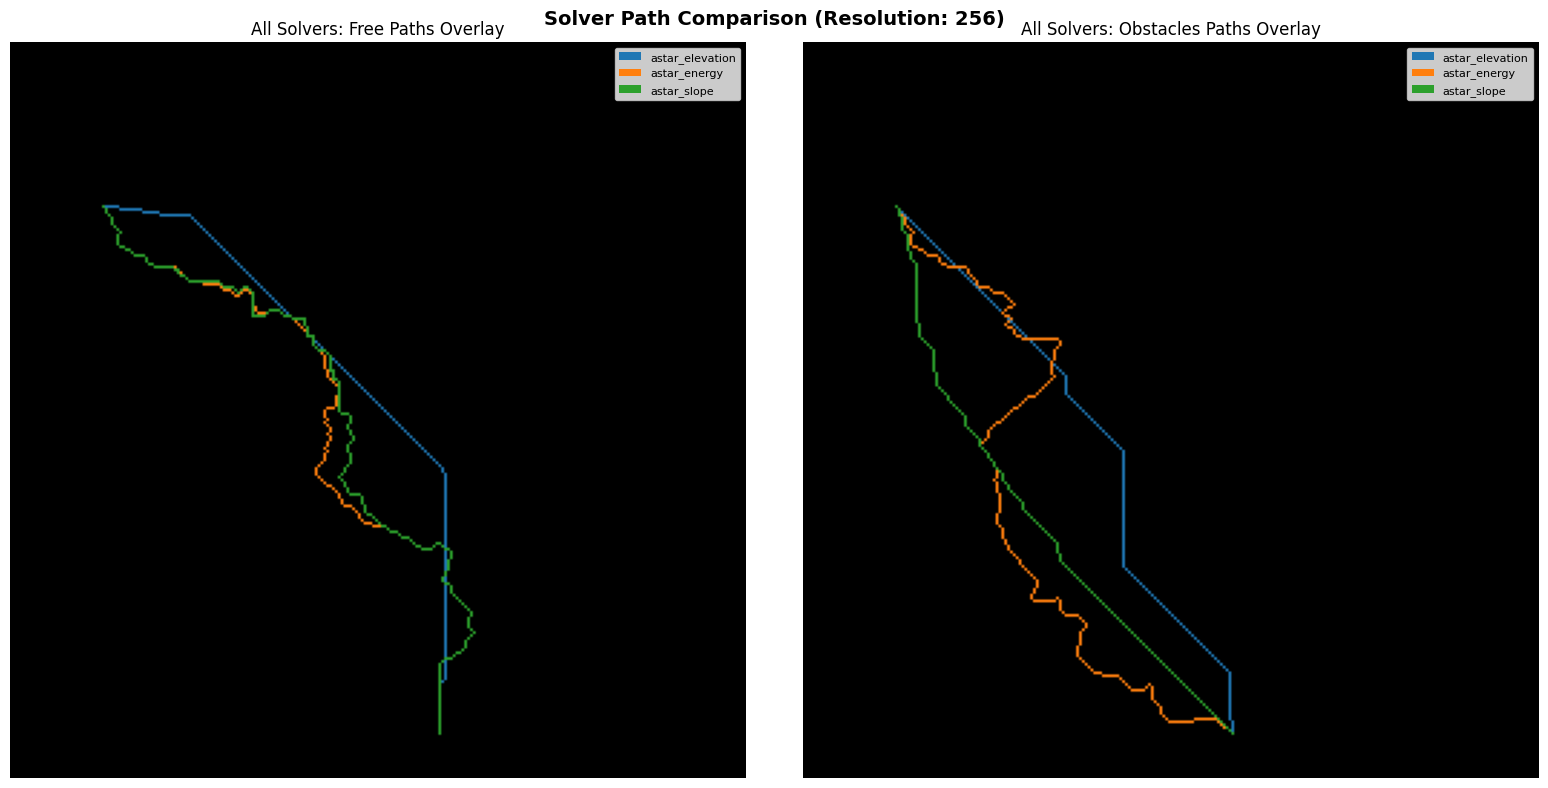

In [22]:
# All solver paths overlaid for comparison
if solvers:
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    # Free paths comparison
    ax = axes[0]
    paths_overlay = np.zeros((marker.shape[0], marker.shape[1], 3), dtype=np.uint8)
    for solver_idx, solver_name in enumerate(solvers):
        free_path = solver_paths[solver_name]["free"]
        color = [int(c * 255) for c in plt.cm.tab10.colors[solver_idx % 10][:3]]
        for x, y in free_path:
            if 0 <= x < paths_overlay.shape[0] and 0 <= y < paths_overlay.shape[1]:
                paths_overlay[x, y] = color
    ax.imshow(paths_overlay)
    ax.set_title("All Solvers: Free Paths Overlay")
    ax.axis("off")
    # Add legend
    from matplotlib.patches import Patch

    legend_elements = [Patch(facecolor=plt.cm.tab10.colors[i % 10], label=s) for i, s in enumerate(solvers)]
    ax.legend(handles=legend_elements, loc="upper right", fontsize=8)

    # Obstacles paths comparison
    ax = axes[1]
    paths_overlay = np.zeros((marker.shape[0], marker.shape[1], 3), dtype=np.uint8)
    for solver_idx, solver_name in enumerate(solvers):
        obs_path = solver_paths[solver_name]["obstacles"]
        color = [int(c * 255) for c in plt.cm.tab10.colors[solver_idx % 10][:3]]
        for x, y in obs_path:
            if 0 <= x < paths_overlay.shape[0] and 0 <= y < paths_overlay.shape[1]:
                paths_overlay[x, y] = color
    ax.imshow(paths_overlay)
    ax.set_title("All Solvers: Obstacles Paths Overlay")
    ax.axis("off")
    ax.legend(handles=legend_elements, loc="upper right", fontsize=8)

    plt.suptitle(f"Solver Path Comparison (Resolution: {RESOLUTION})", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("No solvers configured.")